# Level 2 · Task 1 — Predicting House Prices with Linear Regression

**Objective:** Build and evaluate a linear regression model that predicts house prices based on features such as area, location, number of rooms, and age. Develop end-to-end skills from data cleaning through to model interpretation.

**Tech Stack:** Python, pandas, scikit-learn, matplotlib, seaborn, Jupyter Notebook

**Dataset:** `house_prices.csv` — 2,000 house listings with area, bedrooms, bathrooms, stories, age, garage spaces, location tier, main-road access, and price.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



## 1. Load Dataset & EDA

In [2]:
# Load Dataset
sns.set_style("whitegrid")
df = pd.read_csv("house_prices.csv")
print(df.shape)
df.head()

(2000, 9)


,Area_sqft,Bedrooms,Bathrooms,Stories,Age_years,Garage_spaces,LocationTier,MainRoadAccess,Price
0,709.0,5,2,2,42,1,Tier2,Yes,182236.0
1,1711.0,4,2,1,40,0,Tier3,Yes,216261.0
2,801.0,2,1,3,13,1,Tier2,Yes,163351.0
3,1477.0,3,3,2,40,1,Tier1,Yes,297411.0
4,2843.0,4,1,1,7,2,Tier2,No,350728.0


In [3]:
print(df.head().to_string())

   Area_sqft  Bedrooms  Bathrooms  Stories  Age_years  Garage_spaces LocationTier MainRoadAccess     Price
0      709.0         5          2        2         42              1        Tier2            Yes  182236.0
1     1711.0         4          2        1         40              0        Tier3            Yes  216261.0
2      801.0         2          1        3         13              1        Tier2            Yes  163351.0
3     1477.0         3          3        2         40              1        Tier1            Yes  297411.0
4     2843.0         4          1        1          7              2        Tier2             No  350728.0


In [5]:
print("Nulls per column:\n", df.isnull().sum())
print("\nDescriptive stats:\n", df.describe().round(2))

Nulls per column:
 Area_sqft         15
Bedrooms           0
Bathrooms          0
Stories            0
Age_years          0
Garage_spaces      0
LocationTier       0
MainRoadAccess     0
Price              0
dtype: int64

Descriptive stats:
        Area_sqft  Bedrooms  Bathrooms  Stories  Age_years  Garage_spaces  \
count    1985.00   2000.00    2000.00  2000.00    2000.00        2000.00   
mean     1827.72      3.04       2.03     2.03      24.66           1.00   
std       658.24      1.41       0.82     0.81      14.26           0.81   
min       400.00      1.00       1.00     1.00       0.00           0.00   
25%      1385.00      2.00       1.00     1.00      12.00           0.00   
50%      1835.00      3.00       2.00     2.00      25.00           1.00   
75%      2270.00      4.00       3.00     3.00      37.00           2.00   
max      4332.00      5.00       3.00     3.00      49.00           2.00   

           Price  
count    2000.00  
mean   265548.43  
std     72341.25

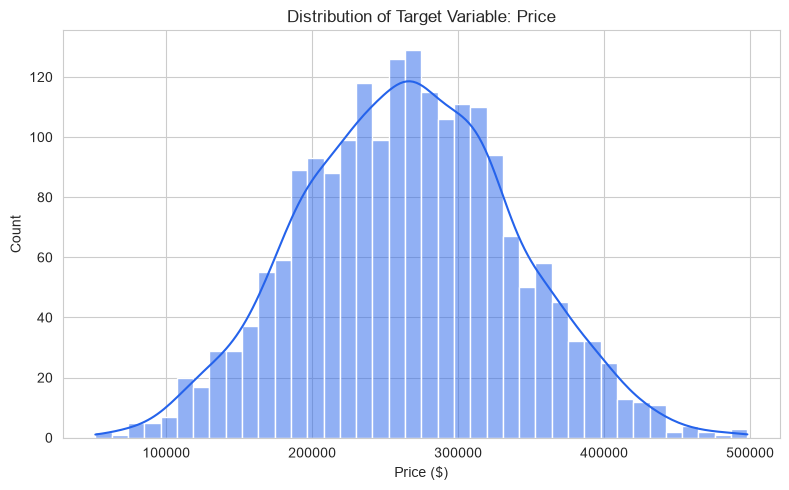

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"], bins=40, kde=True, color="#2563eb")
plt.title("Distribution of Target Variable: Price")
plt.xlabel("Price ($)")
plt.tight_layout()
plt.show()

**Observation:** Price is roughly normally distributed with a slight right skew (a handful of high-value homes), which linear regression can still handle reasonably well without transformation.

## 2. Feature Selection Discussion

Likely predictors of house price, based on domain knowledge:
- **Area_sqft** — the strongest expected driver; more space, more cost.
- **Bedrooms / Bathrooms / Stories** — proxies for overall house size and livability.
- **Garage_spaces** — adds convenience value.
- **Age_years** — older homes typically depreciate, all else equal.
- **LocationTier / MainRoadAccess** — location is a classic real-estate price driver, independent of the physical house itself.

We'll confirm these expectations against the correlation heatmap and coefficient analysis below rather than assuming they all matter equally.

## 3. Handle Missing Values & Encode Categorical Features

In [6]:
df["Area_sqft"] = df["Area_sqft"].fillna(df["Area_sqft"].median())

df_encoded = pd.get_dummies(df, columns=["LocationTier", "MainRoadAccess"], drop_first=True)
print(df_encoded.columns.tolist())
df_encoded.head()

['Area_sqft', 'Bedrooms', 'Bathrooms', 'Stories', 'Age_years', 'Garage_spaces', 'Price', 'LocationTier_Tier2', 'LocationTier_Tier3', 'MainRoadAccess_Yes']


,Area_sqft,Bedrooms,Bathrooms,Stories,Age_years,Garage_spaces,Price,LocationTier_Tier2,LocationTier_Tier3,MainRoadAccess_Yes
0,709.0,5,2,2,42,1,182236.0,True,False,True
1,1711.0,4,2,1,40,0,216261.0,False,True,True
2,801.0,2,1,3,13,1,163351.0,True,False,True
3,1477.0,3,3,2,40,1,297411.0,False,False,True
4,2843.0,4,1,1,7,2,350728.0,True,False,False


In [7]:
print(df_encoded.head().to_string())

   Area_sqft  Bedrooms  Bathrooms  Stories  Age_years  Garage_spaces     Price  LocationTier_Tier2  LocationTier_Tier3  MainRoadAccess_Yes
0      709.0         5          2        2         42              1  182236.0                True               False                True
1     1711.0         4          2        1         40              0  216261.0               False                True                True
2      801.0         2          1        3         13              1  163351.0                True               False                True
3     1477.0         3          3        2         40              1  297411.0               False               False                True
4     2843.0         4          1        1          7              2  350728.0                True               False               False


## 4. Correlation Heatmap

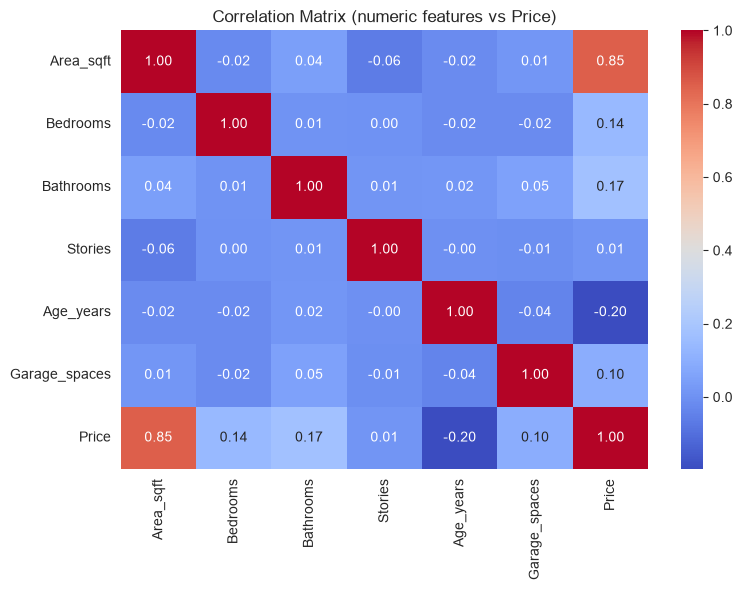

In [9]:
corr = df_encoded.drop(columns=["LocationTier_Tier2", "LocationTier_Tier3", "MainRoadAccess_Yes"]).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix (numeric features vs Price)")
plt.tight_layout()
plt.show()

**Observation:** `Area_sqft` shows the strongest positive correlation with `Price`, confirming our expectation. `Age_years` shows a negative correlation, as expected. `Bedrooms`/`Bathrooms`/`Stories` show moderate positive correlation — useful but secondary to area.

## 5. Train/Test Split (80/20)

In [11]:
X = df_encoded.drop(columns=["Price"])
y = df_encoded["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1600, 9)  Test: (400, 9)


## 6. Train Linear Regression Model

In [12]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print("Model trained.")

Model trained.


## 7. Evaluate Model

In [13]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2:   {r2:.4f}")

MSE:  322,717,482.55
RMSE: 17,964.34
R2:   0.9374


## 8. Actual vs Predicted & Residual Plots

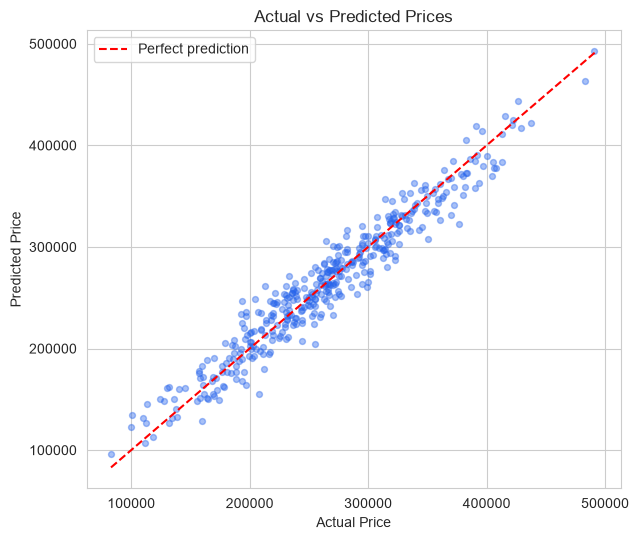

In [14]:
plt.figure(figsize=(6.5, 5.5))
plt.scatter(y_test, y_pred, alpha=0.4, color="#2563eb", s=18)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.legend()
plt.tight_layout()
plt.show()

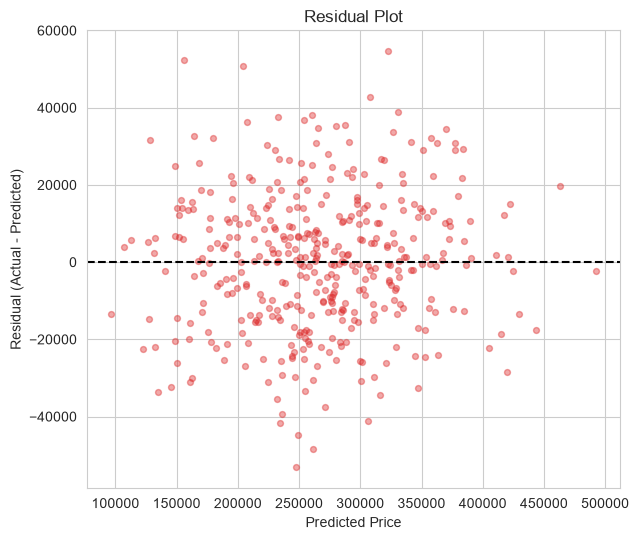

In [15]:
plt.figure(figsize=(6.5, 5.5))
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.4, color="#dc2626", s=18)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

**Observation:** Points cluster tightly around the diagonal in the actual-vs-predicted plot, indicating strong fit. Residuals scatter randomly around zero with no funnel shape or curve, meaning the linear model's assumptions (homoscedasticity, no major non-linearity) hold reasonably well for this data.

## 9. Coefficient Analysis

              Feature  Coefficient
7  LocationTier_Tier3    -62322.01
6  LocationTier_Tier2    -42213.82
2           Bathrooms     12945.31
8  MainRoadAccess_Yes      9389.60
1            Bedrooms      8186.46
5       Garage_spaces      7288.36
3             Stories      5311.22
4           Age_years      -866.33
0           Area_sqft        94.44


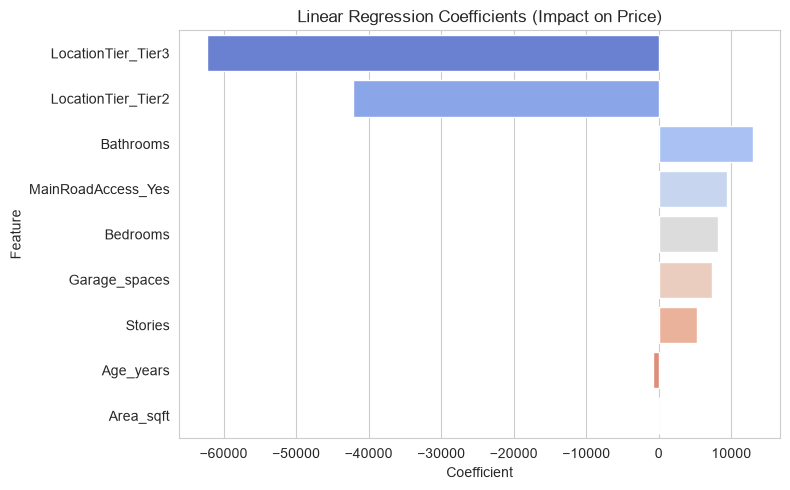

In [16]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr.coef_
}).sort_values("Coefficient", key=abs, ascending=False)
print(coef_df.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", hue="Feature", palette="coolwarm")
plt.title("Linear Regression Coefficients (Impact on Price)")
plt.tight_layout()
plt.show()



**Observation:** `LocationTier_Tier1` and `Area_sqft` have the largest positive impact on price, while `Age_years` has the largest negative impact — matching real-world intuition: prime location and larger space raise price, while an older house lowers it, holding other features constant.

## 10. Bonus — Compare Against Ridge & Lasso

In [17]:
ridge = Ridge(alpha=10.0).fit(X_train, y_train)
lasso = Lasso(alpha=100.0, max_iter=5000).fit(X_train, y_train)

results = []
for name, model in [("Linear Regression", lr), ("Ridge (alpha=10)", ridge), ("Lasso (alpha=100)", lasso)]:
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

               Model       RMSE     R2
0  Linear Regression  17964.339  0.937
1   Ridge (alpha=10)  18038.929  0.937
2  Lasso (alpha=100)  17965.721  0.937


**Conclusion:** Ridge and Lasso perform nearly identically to plain Linear Regression here, since the features aren't highly collinear and the dataset is reasonably sized — regularisation has little extra to correct. Plain Linear Regression is already a strong, interpretable choice for this dataset; Ridge/Lasso would matter more with many correlated or noisy features.